### Simple Hough transform

Calculate the hough transform using the methods of:

Wadge, G., and A. Cross. "Quantitative methods for detecting aligned points: an application to the volcanic vents of the Michoacan-Guanajuato volcanic field, Mexico." Geology 16, no. 9 (1988): 815-818.

The Hough Transform is a method to detect features (like vent alignments) by mapping each point (vent location, $x$, $y$) into a sinusoidal curve, using the transform:

for all theta (angles):

$$\rho = x \cos(\theta) + y \sin(\theta) $$

That is: each vent plots as a sinusoidal curve in the "alignment parameter space". Where two curves intersect, they form an alignment of two vents. Where three curves intersect, there is an alignment of three vents, and so on. Since the vents are not exactly aligned, some "slop" is allowed in the intersection. The slop is $\Delta \rho$, which controls the width of the alignment zone. For example, if $\Delta \rho = 500$ then the alignment zone can be 500 m wide (assuming vent locations are in UTM coordinates).

plotting $\rho$ vs $\theta$ reveals bright spots - points in the parameter space that indicate alignments are present in the map data.

Then plot the alignments. There are three parameters to tune when plotting alignments:

(1) num_peaks: Limits the maximum number of lines (peaks) to detect. Prevents overcrowding the plot with too many lines, especially from noise or weak vent alignment patterns.

Example:
num_peaks=10  # Only the top 10 strongest alignments are returned and plotted

(2) threshold_abs: Sets a minimum number of vents that have to "accumulate at a $\rho$, $\theta$ coordinate to be considered to be a vent alignment.

Example:
threshold_abs=5  # Only consider alignments with at least 5 vents

(3) min_distance: Enforces a minimum distance between peaks (bright spots on the $\rho$ vs. $\theta$ plot). This prevents multiple closely spaced peaks (e.g., neighboring cells in the same line group) from being treated as separate vent alignments. Increase min_dist if you get a lot of alignments which basically look like the same alignment.


written by C. B. Connor (1993)
updated using scipy by C. B. Connor (2025)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

In [2]:
#input the esrp vents and plot them using pandas and matplotlib

vents = pd.read_csv("./vents.csv")
vents.head()

,VentEasting,VentNorthing
0,257696,4812872
1,207822,4795343
2,230267,4799877
3,233778,4795164
4,247417,4803385


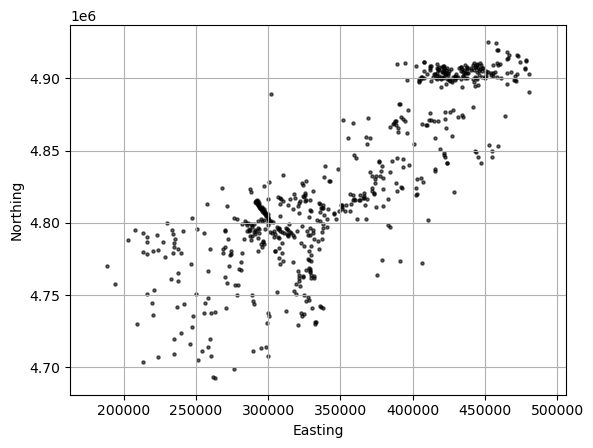

In [3]:
plt.scatter(vents["VentEasting"], vents["VentNorthing"], s=5, c='black', alpha=0.6)
plt.xlabel("Easting")
plt.ylabel("Northing")
plt.axis("equal")
plt.grid("True")
plt.show()

In [4]:
#find the number of vents in the dataset (just check things out and make sure the file is read correctly)
numpts = len(vents)
print("number of vents = ", numpts)

#find the mean easting and northing
xmean = vents["VentEasting"].mean()
ymean = vents["VentNorthing"].mean()
print ("Mean easting = ", xmean, "E")
print ("Mean northing = ", ymean, "N")

# find the maximum distance of any vent from the mean, then pad it a bit
vents["Distance"] = np.sqrt((xmean-vents["VentEasting"])**2 + (ymean-vents["VentNorthing"])**2)
pmax = int(round((vents["Distance"].max() + 1000) / 1000.0) * 1000)
print("Max distance from mean = ", pmax, "m")



number of vents =  618
Mean easting =  352452.5145631068 E
Mean northing =  4827646.634304207 N
Max distance from mean =  187000 m


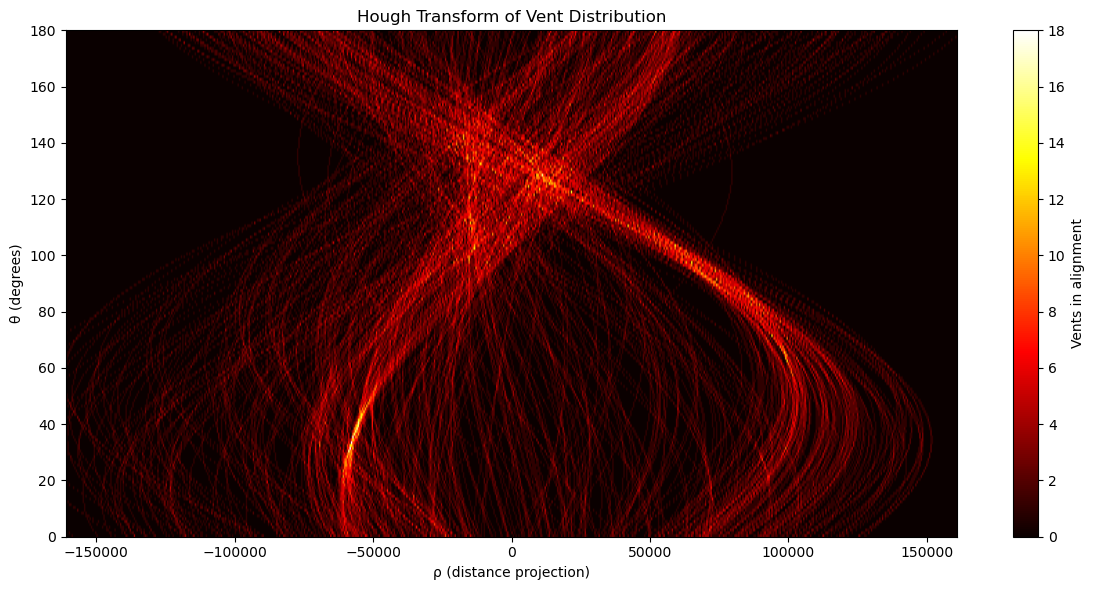

In [5]:
# calculate the rho vs theta plot

easting = vents["VentEasting"].to_numpy()
northing = vents["VentNorthing"].to_numpy()

# Define parameters
num_theta = 180  # angles from 0 to 179 degrees (search all angles for alignments at 1 degree increment)
theta_range = np.deg2rad(np.arange(0, num_theta))
delp = 500        # bin size for rho (how wide can the alignment be? in map units)
pmax = int(round((np.sqrt((easting.max() - xmean)**2 + (northing.max() - ymean)**2)) / 1000.0) * 1000)
rho_bins = np.arange(-pmax, pmax + delp, delp)
num_rho = len(rho_bins)

# Initialize Hough accumulator
hough_acc = np.zeros((num_theta, num_rho), dtype=int)

# Center points
x = easting - xmean
y = northing - ymean

# Hough Transform loop
for xi, yi in zip(x, y):
    for theta_idx, theta in enumerate(theta_range):
        rho = xi * np.cos(theta) + yi * np.sin(theta)
        rho_idx = int((rho + pmax) // delp)
        if 0 <= rho_idx < num_rho:
            hough_acc[theta_idx, rho_idx] += 1

# Plot Hough accumulator (θ vs ρ)
plt.figure(figsize=(12, 6))
extent = [rho_bins[0], rho_bins[-1], 0, num_theta]
plt.imshow(hough_acc, extent=extent, cmap='hot', aspect='auto', origin='lower')
plt.xlabel('ρ (distance projection)')
plt.ylabel('θ (degrees)')
plt.title('Hough Transform of Vent Distribution')
plt.colorbar(label='Vents in alignment')
plt.tight_layout()
plt.show()


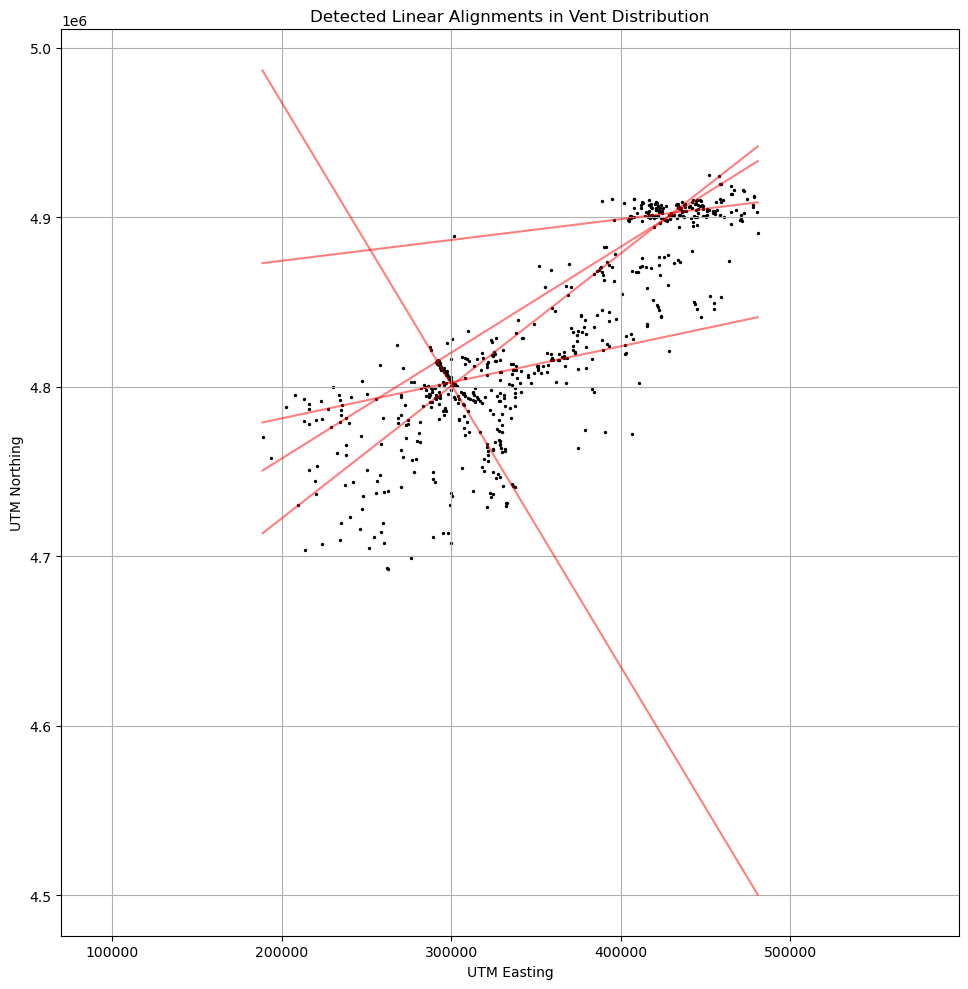

In [6]:
#do the same thing, but this time plot the alignments on a map
# be sure to adjust:
# delp - the parameter bin width (bigger delp = wider and messier alignments allowed)
# min_distance, threshold_abs, ad num_peaks as described above.


# ---------- Step 1: Compute Hough Transform ----------
num_theta = 180
theta_range = np.deg2rad(np.arange(0, num_theta))
delp = 500
pmax = int(round((np.sqrt((easting.max() - xmean)**2 + (northing.max() - ymean)**2)) / 1000.0) * 1000)
rho_bins = np.arange(-pmax, pmax + delp, delp)
num_rho = len(rho_bins)

hough_acc = np.zeros((num_theta, num_rho), dtype=int)
x = easting - xmean
y = northing - ymean

for xi, yi in zip(x, y):
    for theta_idx, theta in enumerate(theta_range):
        rho = xi * np.cos(theta) + yi * np.sin(theta)
        rho_idx = int((rho + pmax) // delp)
        if 0 <= rho_idx < num_rho:
            hough_acc[theta_idx, rho_idx] += 1

# ---------- Step 2: Find Peaks in Hough Space ----------
from skimage.feature import peak_local_max
# Find local maxima in Hough space
peaks = peak_local_max(hough_acc, min_distance=10, threshold_abs=10, num_peaks=5)

# ---------- Step 3: Plot Original Vents and Detected Lines ----------
plt.figure(figsize=(10, 10))
plt.scatter(easting, northing, s=2, color='black', label='Vents')

# Overlay lines from (theta, rho) peaks
for peak in peaks:
    theta_idx, rho_idx = peak
    theta = theta_range[theta_idx]
    rho = rho_bins[rho_idx]

    # Convert (theta, rho) to a line: x cos(θ) + y sin(θ) = rho
    # Rearranged: y = (-cos(θ)/sin(θ))x + (rho / sin(θ))
    if np.sin(theta) != 0:
        slope = -np.cos(theta) / np.sin(theta)
        intercept = rho / np.sin(theta)
        x_vals = np.linspace(easting.min(), easting.max(), 1000)
        y_vals = slope * (x_vals - xmean) + intercept + ymean
        plt.plot(x_vals, y_vals, 'r-', alpha=0.5)
    else:
        # Vertical line case: x = rho / cos(theta)
        x_line = rho / np.cos(theta) + xmean
        plt.axvline(x_line, color='r', linestyle='--', alpha=0.5)

plt.xlabel('UTM Easting')
plt.ylabel('UTM Northing')
plt.title('Detected Linear Alignments in Vent Distribution')
plt.grid(True)
plt.axis('equal')
plt.tight_layout()
plt.show()
